# Laboratory 4 homework

## Dataset preparation (1 point)

In [1]:
import os

import polars as pl

DATA_DIR = "./abo-images-small/images"

In [2]:
df_images = pl.read_csv(f"{DATA_DIR}/metadata/images.csv.gz")
df_images = df_images.with_columns(
    path=pl.format(DATA_DIR + "/small/{}", pl.col("path"))
).filter(
    pl.col("height") >= 1000,
    pl.col("width") >= 1000,
    pl.col("path").map_elements(os.path.exists, return_dtype=pl.Boolean),
)
image_paths = df_images["path"].to_list()

## Model Selection and Understanding (1 point)

Answers:
- Vector size: 512.
- Model type: CLIP, a multimodal model that puts images and text in the same vector space.
- `ViT`: Vision Transformer, the image encoder.
- `B`: Base, the model size.
- `32`: patch size, the image is cut into 32x32 pixel patches.

## Database setup (2 points)

In [3]:
from sqlalchemy.engine import URL

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db",
)

In [4]:
from sqlalchemy import create_engine

engine = create_engine(db_url)

In [5]:
from typing import ClassVar

from pgvector.sqlalchemy import Vector
from sqlalchemy import String
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column


# Create the base class for the table definition
class Base(DeclarativeBase):
    __abstract__ = True


class Img(Base):
    __tablename__ = "images"
    __table_args__: ClassVar = {"extend_existing": True}

    VECTOR_LENGTH: int = 512

    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(256))
    embedding: Mapped[list[float]] = mapped_column(Vector(VECTOR_LENGTH))


# Create table
Base.metadata.create_all(engine)

## Image vectorization (3 points)

In [6]:
import torch
from sentence_transformers import SentenceTransformer

checkpoint = "clip-ViT-B-32"
device = (
    "cuda"
    if torch.cuda.is_available()
    else ("mps" if torch.backends.mps.is_available() else "cpu")
)
print(f"Using device: {device}")
model = SentenceTransformer(checkpoint, device=device)

Using device: mps


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


In [7]:
from itertools import islice

import torch
from PIL import Image
from sentence_transformers import SentenceTransformer
from sqlalchemy.orm import Session
from tqdm.notebook import tqdm


def batched(iterable, n):
    it = iter(iterable)
    while batch := tuple(islice(it, n)):
        yield batch


MAX_IMAGES = len(image_paths)
BATCH_SIZE = 64


def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()


def vectorize_images(engine, model, image_paths):
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(image_paths[:MAX_IMAGES], BATCH_SIZE):
            images = [Image.open(path) for path in images_paths_batch]

            embeddings = model.encode(images)

            imgs = [
                Img(image_path=path, embedding=embedding)
                for path, embedding in zip(images_paths_batch, embeddings)
            ]

            insert_images(engine, imgs)

            pbar.update(len(imgs))

In [8]:
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)
vectorize_images(engine, model, image_paths)

  0%|          | 0/342878 [00:00<?, ?it/s]

## Search and results display (3 points)

In [9]:
import matplotlib.pyplot as plt
from sqlalchemy import select


class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model

    def __call__(self, image_description: str, k: int):
        found_images = self.find_similar_images(image_description, k)
        self.display_images(found_images)

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = self.model.encode(image_description)

        with Session(self.engine) as session:
            query = (
                select(Img.image_path)
                .where(Img.id <= MAX_IMAGES)
                .order_by(Img.embedding.cosine_distance(image_embedding))
                .limit(k)
            )
            result = session.scalars(query).all()
        return result

    def display_images(self, images):
        fig, axes = plt.subplots(1, len(images), figsize=(15, 5))

        for i, img_path in enumerate(images):
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i + 1}")

        plt.show()

In [10]:
image_search = ImageSearch(engine, model)

MAX_IMAGES = 10000
car


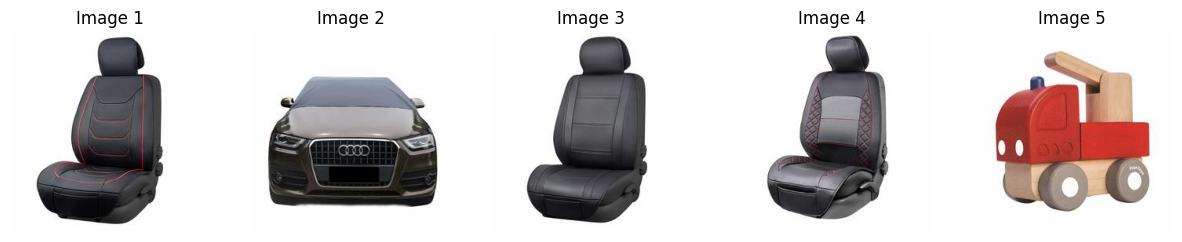

delicious italian food


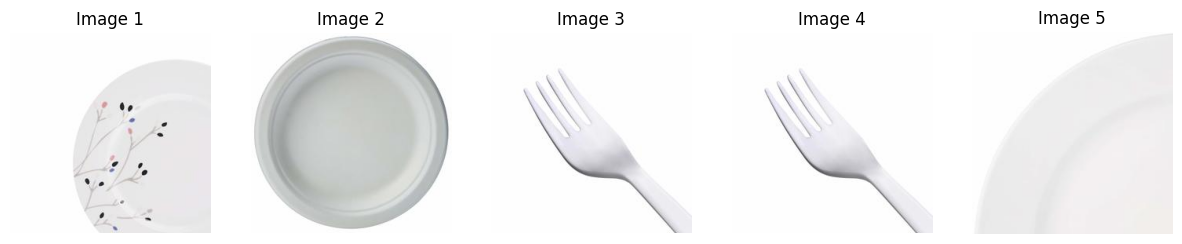

new york


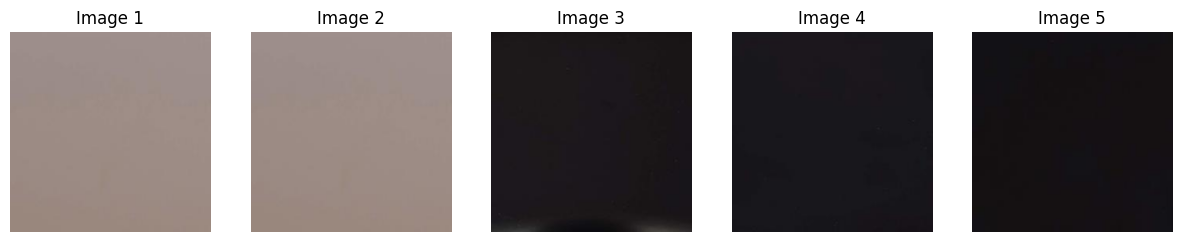

animal


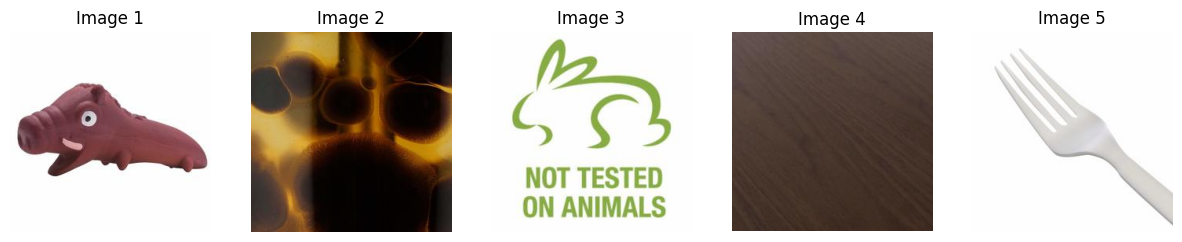

cute puppy


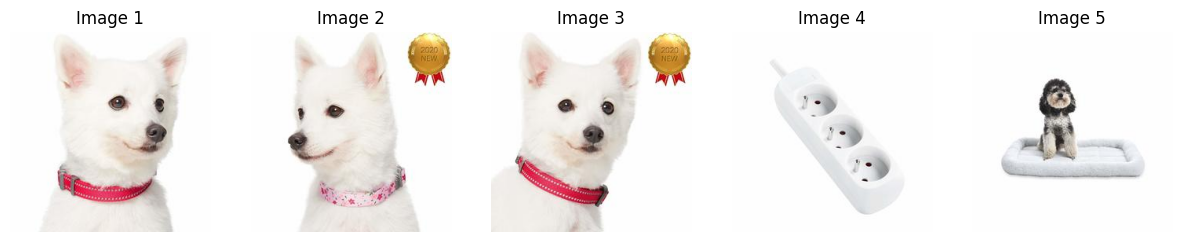

MAX_IMAGES = 100000
car


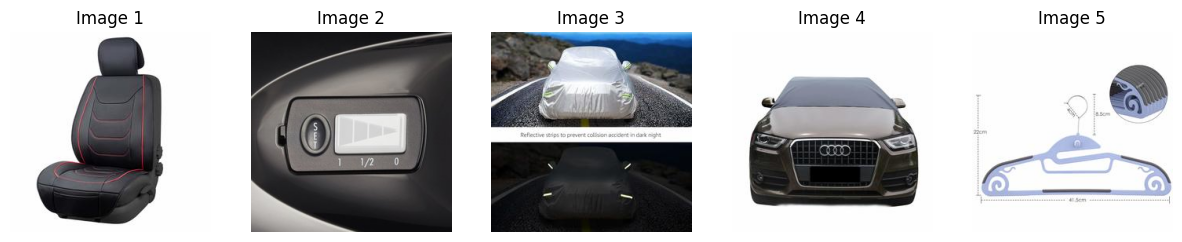

delicious italian food


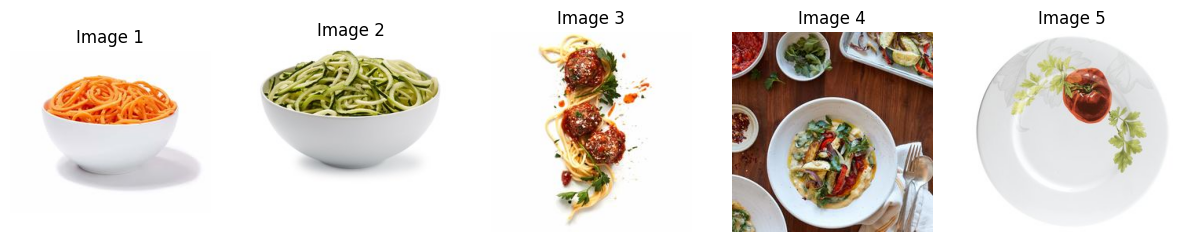

new york


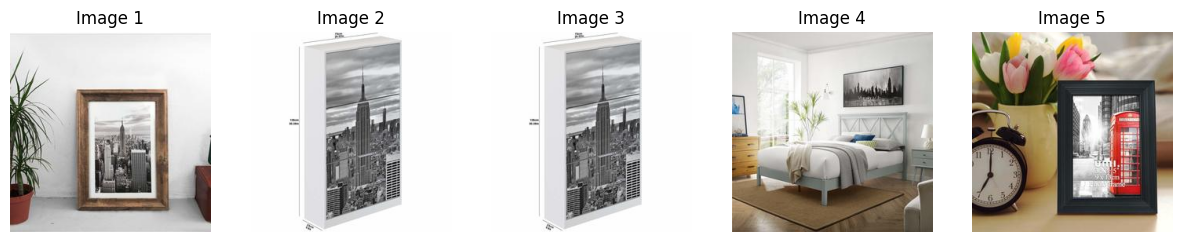

animal


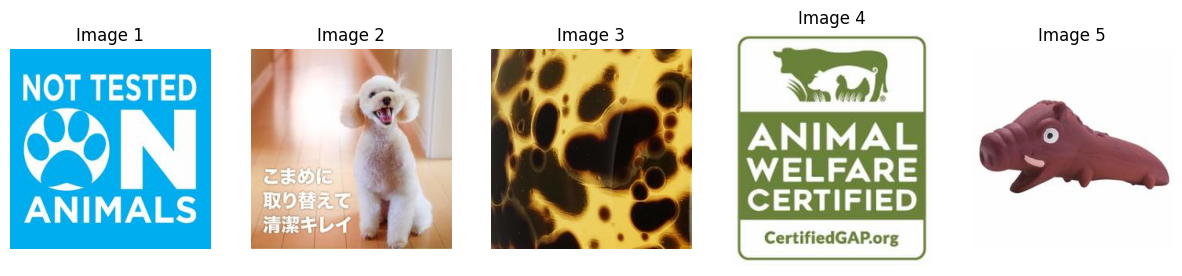

cute puppy


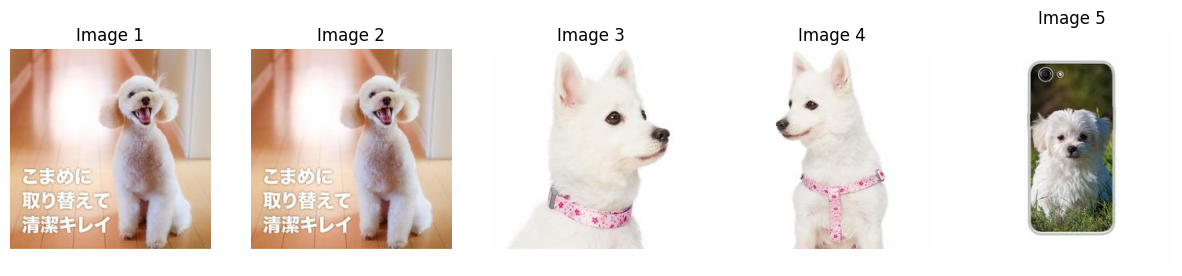

MAX_IMAGES = 342878
car


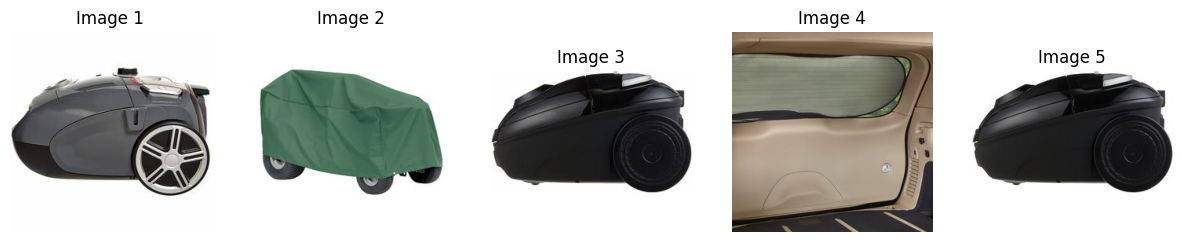

delicious italian food


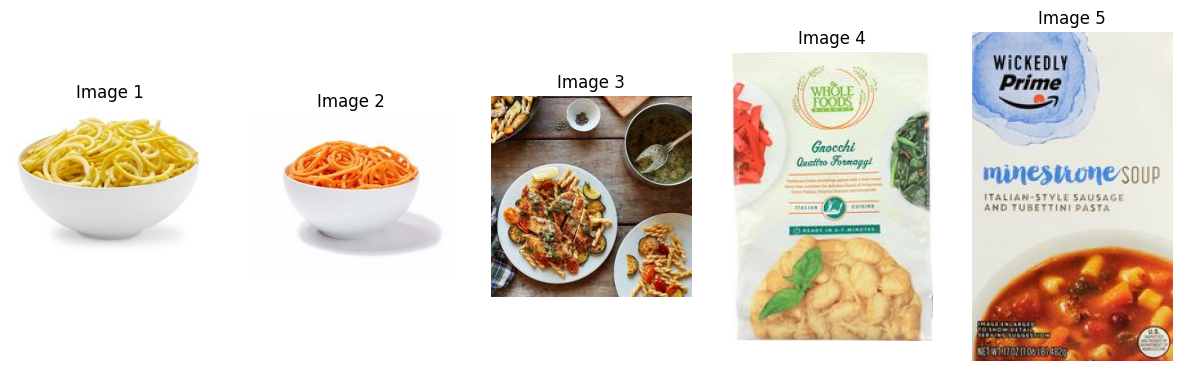

new york


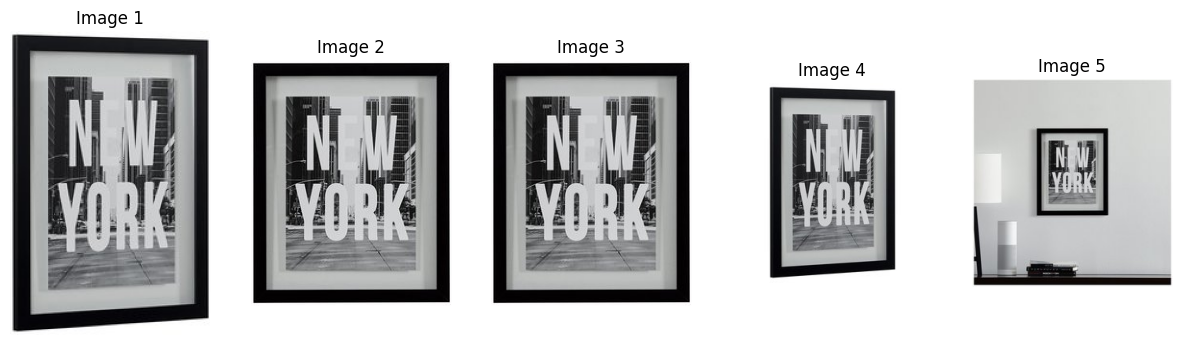

animal


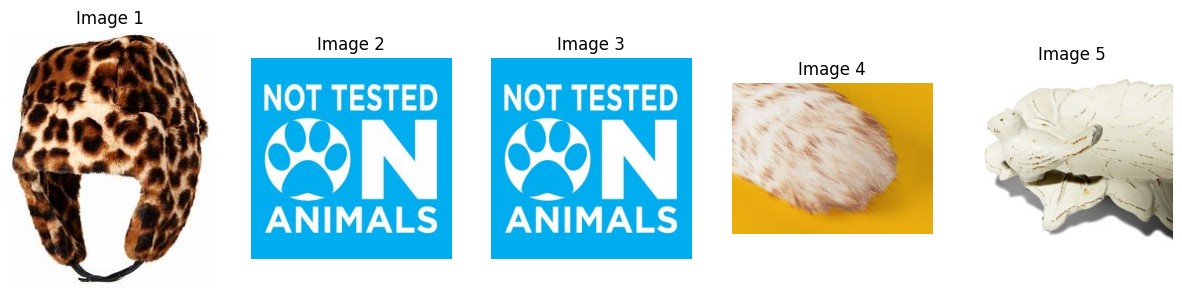

cute puppy


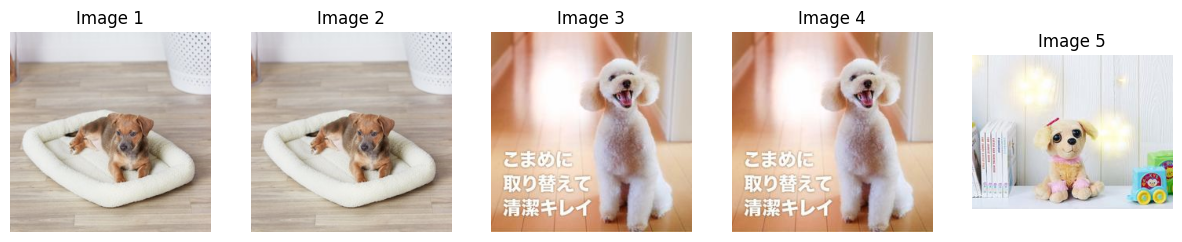

In [11]:
QUERIES = ["car", "delicious italian food", "new york", "animal", "cute puppy"]

for MAX_IMAGES in [10_000, 100_000, len(image_paths)]:
    print(f"MAX_IMAGES = {MAX_IMAGES}")
    for query in QUERIES:
        print(query)
        image_search(query, k=5)

Answers:
- Are results relevant? Mostly yes. "cute puppy", "delicious italian food" and "new york" give good matches. The dataset is Amazon products, so "car" mostly returns car accessories and "animal" returns logos and animal-print items.
- Do you see more accurate results for larger datasets? Mostly yes. With 10,000 images, "new york" returns blank color squares and "delicious italian food" returns empty plates and forks. With 100,000 and 342,878 both return real matches, and the full set finds literal "NEW YORK" prints and Italian food products. It is not always better: on the full set "car" ranks vacuum cleaners first, and "animal" stays weak at every size.